# 3 · Predict: how many installs will an idea get?

**Syllabus:** Module 4 (simple, multiple and polynomial regression, KNN, decision
trees, model evaluation).

**Target:** log10(installs). An error of 1.0 means the prediction is off by a factor
of ten.

**The trap this chapter is about: leakage.** The number of reviews predicts installs
almost perfectly (chapter 2: Spearman 0.97). But an idea has no reviews. A model that
uses them looks excellent and is useless for judging an idea. So the models come in
two groups:

* **After launch** (leaked): use reviews and rating. Shown to measure the trap.
* **Before launch** (honest): use only what is known about an idea: its category,
  its content rating, free or paid, the price, and the apps whose names resemble it.

**Protocol:** 60/20/20 split, stratified by category, fixed seed. Choices (polynomial
degree, K, tree depth) are made on validation; test is used once.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import common as C
import engine as E

C.style()
apps = C.load_apps()
apps["split"] = C.split(apps)
apps["log_reviews"] = np.log10(apps["reviews"] + 1)
apps["log_price"] = np.log1p(apps["price"])
apps["rating_missing"] = apps["rating"].isna().astype(int)
apps["rating_f"] = apps["rating"].fillna(apps.loc[apps["split"] == "train", "rating"].median())
tr, va, te = (apps[apps["split"] == s] for s in ["train", "val", "test"])
y = "log_installs"
print({s: int((apps["split"] == s).sum()) for s in ["train", "val", "test"]})
C.record("predict.split_sizes", {s: int((apps["split"] == s).sum()) for s in ["train", "val", "test"]})


def scores(pred, d):
    return {"rmse": float(np.sqrt(mean_squared_error(d[y], pred))), "mae": float(mean_absolute_error(d[y], pred)),
            "r2": float(r2_score(d[y], pred))}


results = {}

{'train': 5795, 'val': 1932, 'test': 1932}


## 3.1 After launch: the leaked models

**Simple linear regression** fits a straight line, installs = a + b·reviews (both on
log scales), by least squares. **Polynomial regression** adds reviews², reviews³…, so
the line can bend; the degree is chosen on validation. **Multiple linear regression**
uses several inputs at once.

validation RMSE by degree: {1: 0.554, 2: 0.53, 3: 0.527, 4: 0.527, 5: 0.527}


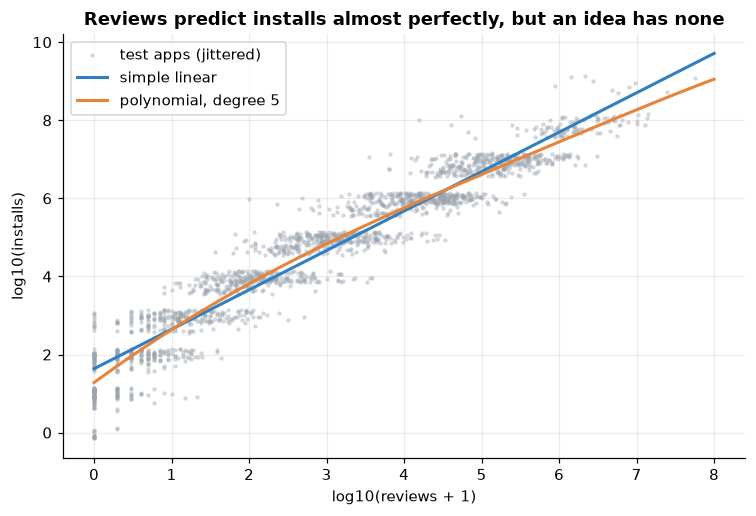

In [2]:
lin = LinearRegression().fit(tr[["log_reviews"]], tr[y])
results["Simple linear: reviews (after launch)"] = scores(lin.predict(te[["log_reviews"]]), te)
deg_val = {}
for d in [1, 2, 3, 4, 5]:
    m = make_pipeline(PolynomialFeatures(d), LinearRegression()).fit(tr[["log_reviews"]], tr[y])
    deg_val[d] = scores(m.predict(va[["log_reviews"]]), va)["rmse"]
best_deg = min(deg_val, key=deg_val.get)
poly = make_pipeline(PolynomialFeatures(best_deg), LinearRegression()).fit(tr[["log_reviews"]], tr[y])
results[f"Polynomial (degree {best_deg}): reviews (after launch)"] = scores(poly.predict(te[["log_reviews"]]), te)
post = ["log_reviews", "rating_f", "rating_missing", "log_price", "paid"]
mlr = LinearRegression().fit(tr[post], tr[y])
results["Multiple linear: reviews, rating, price (after launch)"] = scores(mlr.predict(te[post]), te)
print("validation RMSE by degree:", {k: round(v, 3) for k, v in deg_val.items()})
C.record("predict.poly_val_rmse", deg_val); C.record("predict.poly_degree", best_deg)
C.record("predict.simple_linear", {"intercept": float(lin.intercept_), "slope": float(lin.coef_[0])})

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(te["log_reviews"], te[y] + np.random.default_rng(C.SEED).uniform(-0.15, 0.15, len(te)), s=4, alpha=0.3,
           color=C.PALETTE["muted"], label="test apps (jittered)")
xs = pd.DataFrame({"log_reviews": np.linspace(0, 8, 200)})
ax.plot(xs, lin.predict(xs), color=C.PALETTE["main"], lw=2, label="simple linear")
ax.plot(xs, poly.predict(xs), color=C.PALETTE["accent"], lw=2, label=f"polynomial, degree {best_deg}")
ax.set_xlabel("log10(reviews + 1)"); ax.set_ylabel("log10(installs)")
ax.set_title("Reviews predict installs almost perfectly, but an idea has none"); ax.legend()
C.save(fig, "predict_leak")

## 3.2 Before launch: the honest models

* **Baseline:** predict the training mean for everyone.
* **Category mean:** predict the average of the idea's category.
* **Multiple linear, pre-launch:** category and content rating (one-hot), free/paid
  and log price.
* **KNN on names:** the K apps whose names are most similar (TF-IDF character n-grams,
  cosine similarity), averaged with similarity as weight. This is how the viability
  engine measures demand, so K is chosen here.
* **Decision tree** and **multiple linear** on the pre-launch inputs plus the
  neighbourhood signals (neighbours' installs, rating, and how close they are).

validation RMSE by K: {5: 1.742, 10: 1.69, 25: 1.649, 50: 1.662, 100: 1.691, 200: 1.722} -> K = 25


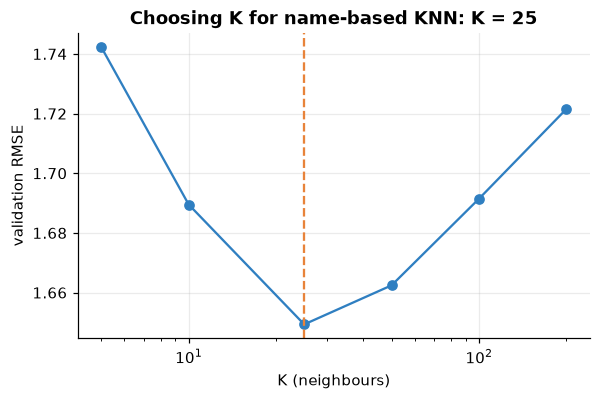

In [3]:
results["Baseline: training mean"] = scores(np.full(len(te), tr[y].mean()), te)
cat_mean = tr.groupby("category")[y].mean()
results["Category mean"] = scores(te["category"].map(cat_mean).fillna(tr[y].mean()), te)

pre = ColumnTransformer([("oh", OneHotEncoder(handle_unknown="ignore"), ["category", "content"]),
                         ("num", StandardScaler(), ["paid", "log_price"])])
mlr_pre = make_pipeline(pre, LinearRegression()).fit(tr, tr[y])
results["Multiple linear: category, content, price (before launch)"] = scores(mlr_pre.predict(te), te)

eng = E.fit(tr.drop(columns="split"))                       # the engine sees training apps only
Xva = eng.vec.transform(va["app"].map(E.normalise))
k_val = {}
for k in [5, 10, 25, 50, 100, 200]:
    sim, idx = eng.neighbours(Xva, k=k)
    k_val[k] = scores(eng.signals(sim, idx)["nb_demand"], va)["rmse"]
best_k = min(k_val, key=k_val.get)
print("validation RMSE by K:", {k: round(v, 3) for k, v in k_val.items()}, "-> K =", best_k)
C.record("predict.knn_val_rmse", k_val); C.record("predict.knn_k", best_k)
assert best_k == E.K, f"engine.K is {E.K} but validation chose {best_k}: update engine.K"

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(list(k_val), list(k_val.values()), marker="o", color=C.PALETTE["main"])
ax.set_xscale("log"); ax.set_xlabel("K (neighbours)"); ax.set_ylabel("validation RMSE")
ax.axvline(best_k, color=C.PALETTE["accent"], ls="--"); ax.set_title(f"Choosing K for name-based KNN: K = {best_k}")
C.save(fig, "predict_knn_k")


def with_signals(d, exclude=None):
    X = eng.vec.transform(d["app"].map(E.normalise))
    sim, idx = eng.neighbours(X, exclude=exclude)
    return d.reset_index(drop=True).join(eng.signals(sim, idx))


# Training apps are described by their neighbours *other than themselves* (leave one out).
trs = with_signals(tr, exclude=np.arange(len(tr)))
vas, tes = with_signals(va), with_signals(te)
results[f"KNN on names (K = {best_k})"] = scores(tes["nb_demand"], tes)

feats = ["category", "content", "paid", "log_price", "nb_demand", "nb_crowding", "nb_rating"]
pre2 = ColumnTransformer([("oh", OneHotEncoder(handle_unknown="ignore"), ["category", "content"]),
                          ("num", StandardScaler(), ["paid", "log_price", "nb_demand", "nb_crowding", "nb_rating"])])
mlr2 = make_pipeline(pre2, LinearRegression()).fit(trs[feats], trs[y])
results["Multiple linear: pre-launch + neighbourhood"] = scores(mlr2.predict(tes[feats]), tes)

depth_val = {}
for dep in [2, 3, 4, 5, 6, 8, 10, 12]:
    t = make_pipeline(pre2, DecisionTreeRegressor(max_depth=dep, min_samples_leaf=20, random_state=C.SEED)).fit(trs[feats], trs[y])
    depth_val[dep] = scores(t.predict(vas[feats]), vas)["rmse"]
best_depth = min(depth_val, key=depth_val.get)
tree = make_pipeline(pre2, DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=20, random_state=C.SEED)).fit(trs[feats], trs[y])
results[f"Decision tree (depth {best_depth}): pre-launch + neighbourhood"] = scores(tree.predict(tes[feats]), tes)
C.record("predict.tree_val_rmse", depth_val); C.record("predict.tree_depth", best_depth)

## 3.3 Every model on the same test apps

                                                     rmse    mae     r2  \
Multiple linear: reviews, rating, price (after ...  0.493  0.380  0.935   
Polynomial (degree 5): reviews (after launch)       0.518  0.402  0.928   
Simple linear: reviews (after launch)               0.549  0.434  0.919   
Multiple linear: pre-launch + neighbourhood         1.523  1.228  0.378   
Decision tree (depth 6): pre-launch + neighbour...  1.564  1.248  0.344   
KNN on names (K = 25)                               1.641  1.340  0.277   
Multiple linear: category, content, price (befo...  1.759  1.462  0.170   
Category mean                                       1.821  1.518  0.110   
Baseline: training mean                             1.933  1.637 -0.002   

                                                                    group  
Multiple linear: reviews, rating, price (after ...  after launch (leaked)  
Polynomial (degree 5): reviews (after launch)       after launch (leaked)  
Simple linear: review

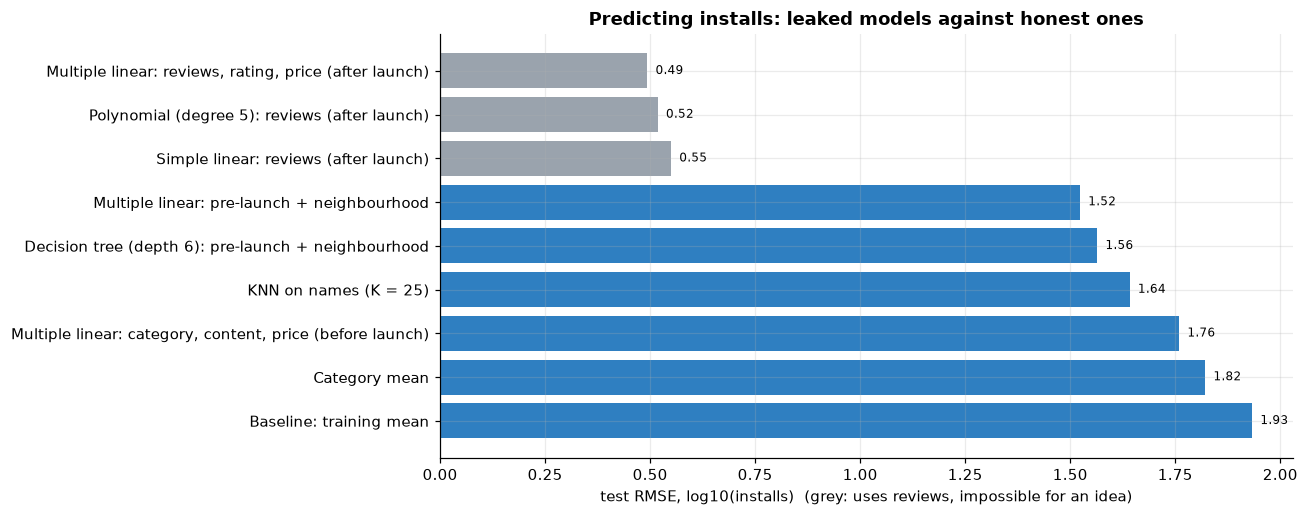

In [4]:
table = pd.DataFrame(results).T.sort_values("rmse")
table["group"] = np.where(table.index.str.contains("after launch"), "after launch (leaked)", "before launch")
print(table.round(3))
C.record("predict.table", table.round(4).to_dict(orient="index"))

fig, ax = plt.subplots(figsize=(10, 5))
colors = [C.PALETTE["muted"] if g.startswith("after") else C.PALETTE["main"] for g in table["group"]]
ax.barh(table.index, table["rmse"], color=colors)
for i, v in enumerate(table["rmse"]):
    ax.text(v + 0.02, i, f"{v:.2f}", va="center", fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("test RMSE, log10(installs)  (grey: uses reviews, impossible for an idea)")
ax.set_title("Predicting installs: leaked models against honest ones")
C.save(fig, "predict_ranking")

honest = table[table["group"] == "before launch"]
best_honest = honest.index[0]
gain = 1 - honest.loc[best_honest, "rmse"] / table.loc["Baseline: training mean", "rmse"]
C.record("predict.best_honest", {"model": best_honest, **honest.loc[best_honest, ["rmse", "mae", "r2"]].to_dict(),
                                 "rmse_cut_vs_baseline_pct": round(float(gain * 100), 1)})
C.record("predict.best_leaked", {"model": table.index[0], **table.iloc[0][["rmse", "mae", "r2"]].to_dict()})
print(f"best honest model: {best_honest}, RMSE cut by {gain:.0%} against the baseline")

**Reading the table.** With reviews, R² is close to 1: the model is almost perfect,
and useless for an idea. Without them, the best model explains a modest share of the
variation. That is the honest answer: **most of what decides an app's installs is
not visible before launch** (execution, marketing, timing, luck). What an idea can be
judged on is its category and its neighbourhood, and those do carry real signal,
above the baseline.

## 3.4 What the tree uses

nb_demand                  0.766
paid                       0.116
log_price                  0.033
category_BUSINESS          0.021
category_MEDICAL           0.014
category_GAME              0.013
nb_crowding                0.013
nb_rating                  0.010
content_Everyone           0.009
content_Teen               0.004
category_FAMILY            0.001
category_ART_AND_DESIGN    0.000
dtype: float64


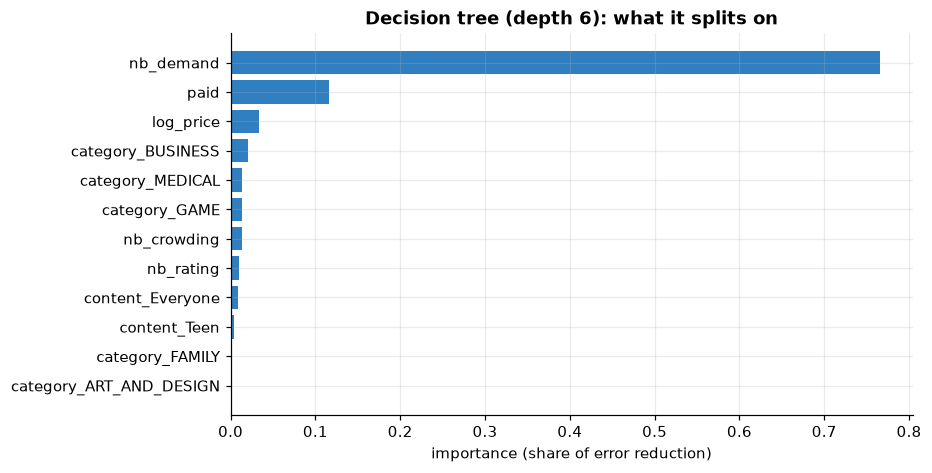

In [5]:
names = tree[0].get_feature_names_out()
imp = pd.Series(tree[-1].feature_importances_, names).sort_values(ascending=False).head(12)
imp.index = imp.index.str.replace("oh__", "").str.replace("num__", "")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp.index[::-1], imp.values[::-1], color=C.PALETTE["main"])
ax.set_xlabel("importance (share of error reduction)"); ax.set_title(f"Decision tree (depth {best_depth}): what it splits on")
C.save(fig, "predict_importance")
C.record("predict.tree_importance", imp.round(4).to_dict())
print(imp.round(3))